# Pairs Trading Research Coca Cola and Pepsi Co

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [5]:
start_date = "2024-01-01"
end_date = "2026-01-01"


data_coca = yf.download("KO", start=start_date, end=end_date, auto_adjust=True, threads=True, progress=False)['Close']
data_pepsi = yf.download("PEP", start=start_date, end=end_date, auto_adjust=True, threads=True, progress=False)['Close']

In [ ]:
data = pd.concat([data_coca, data_pepsi], axis=1)

In [20]:
data.head()

Ticker,KO,PEP
Date,,
2024-01-02,55.309338,156.347290
2024-01-03,55.438778,156.383469
2024-01-04,55.253860,155.045212
2024-01-05,55.170647,152.757568
2024-01-08,55.577473,152.911270


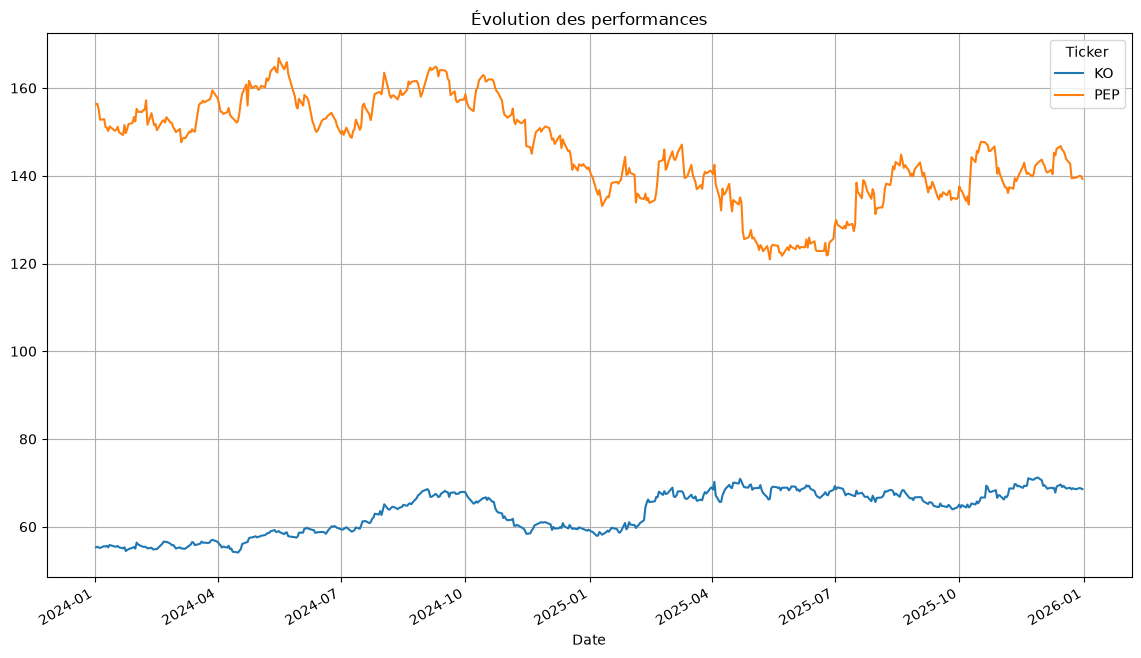

In [14]:
data.plot(figsize=(14,8))
plt.title('Évolution des performances')
plt.grid(True)

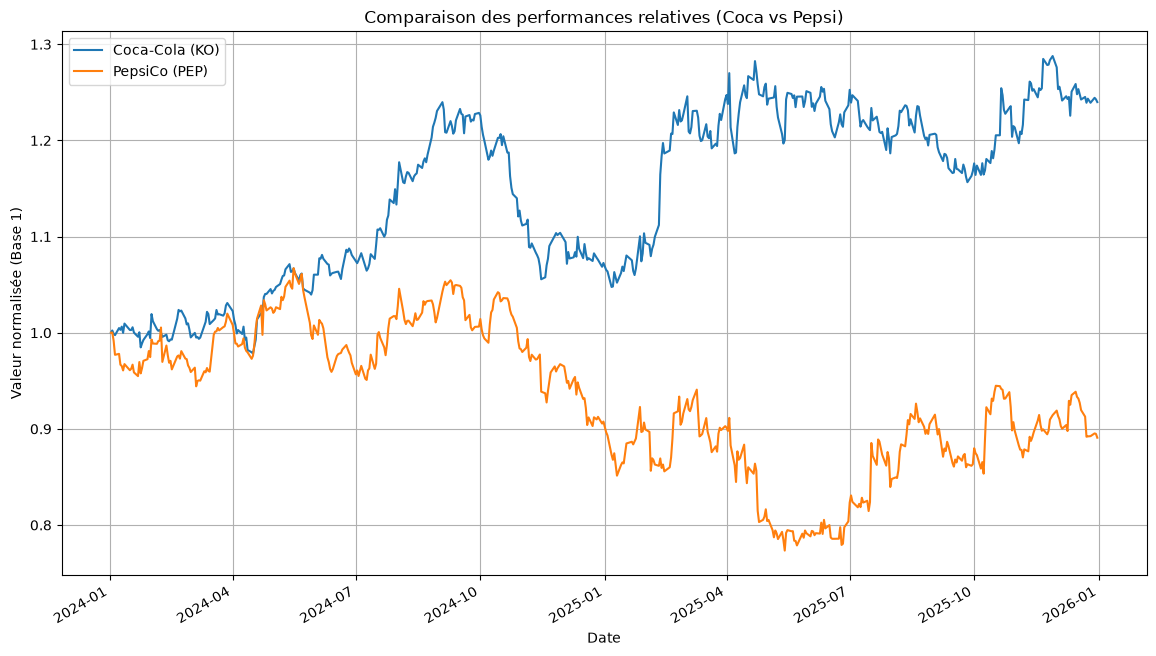

In [12]:
normalized_data = data / data.iloc[0]

normalized_data.plot(figsize=(14, 8))

plt.title("Comparaison des performances relatives (Coca vs Pepsi)")
plt.ylabel("Valeur normalisée (Base 1)")
plt.xlabel("Date")
plt.legend(["Coca-Cola (KO)", "PepsiCo (PEP)"])
plt.grid(True)
plt.show()

In [18]:
returns = data.pct_change().dropna()
correlation_matrix = returns.corr()
print(correlation_matrix)

Ticker        KO       PEP
Ticker                    
KO      1.000000  0.579153
PEP     0.579153  1.000000


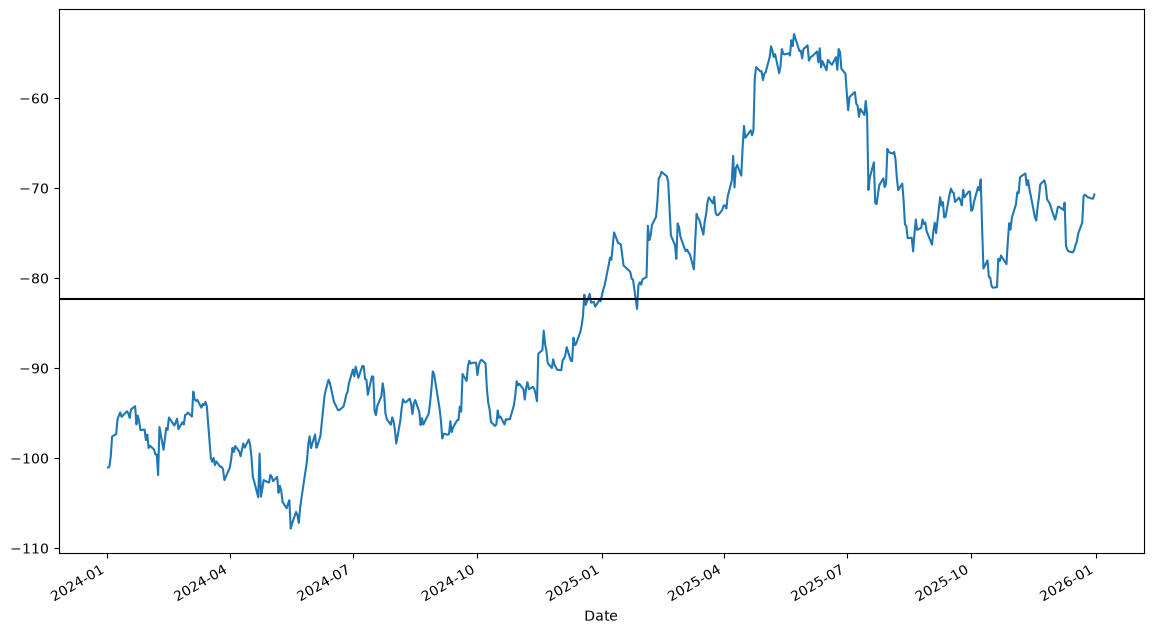

In [23]:
spread = data['KO'] - data['PEP']
spread.plot(label='Spread', figsize=(14,8))
plt.axhline(spread.mean(), c='black')

### Normalization with a Z score

In [24]:
def zscore(stocks):
    return(stocks-stocks.mean())/np.std(stocks)

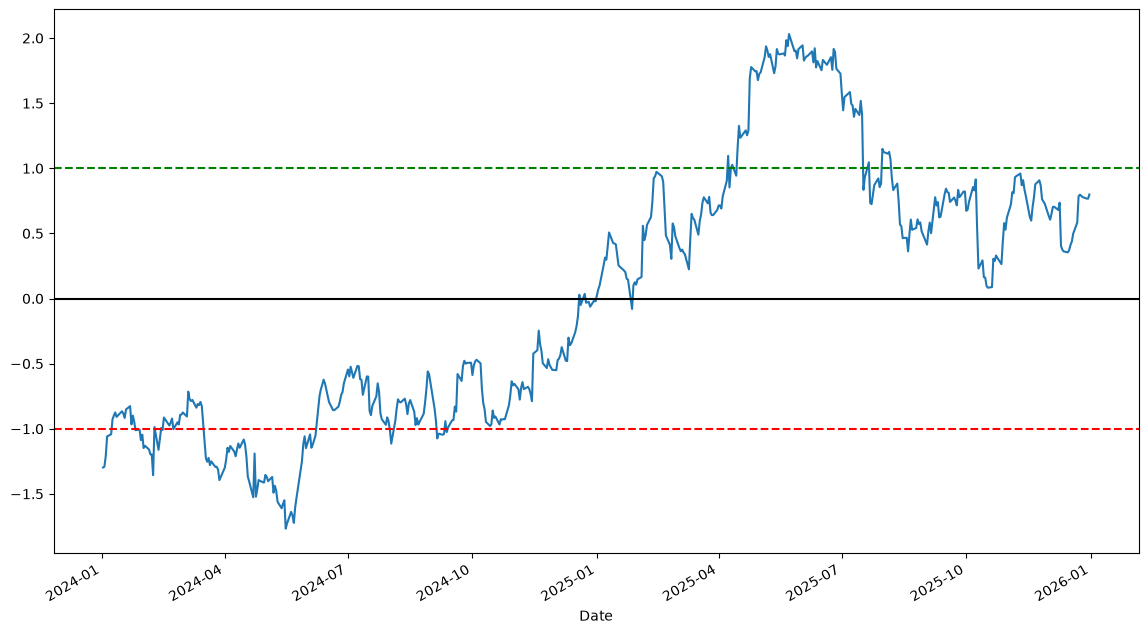

In [25]:
zscore(spread).plot(figsize=(14,8))
plt.axhline(zscore(spread).mean(), color='black')
plt.axhline(1.0, c='g', ls='--')
plt.axhline(-1.0, c='r', ls='--')

### Calculating 1d Moving Average of the Price Spread

In [27]:
spread_mavg1 = spread.rolling(1).mean()

spread_mavg30 = spread.rolling(30).mean()

std_30 = spread.rolling(30).std()


zscore_30_1 = (spread_mavg1 - spread_mavg30) / std_30

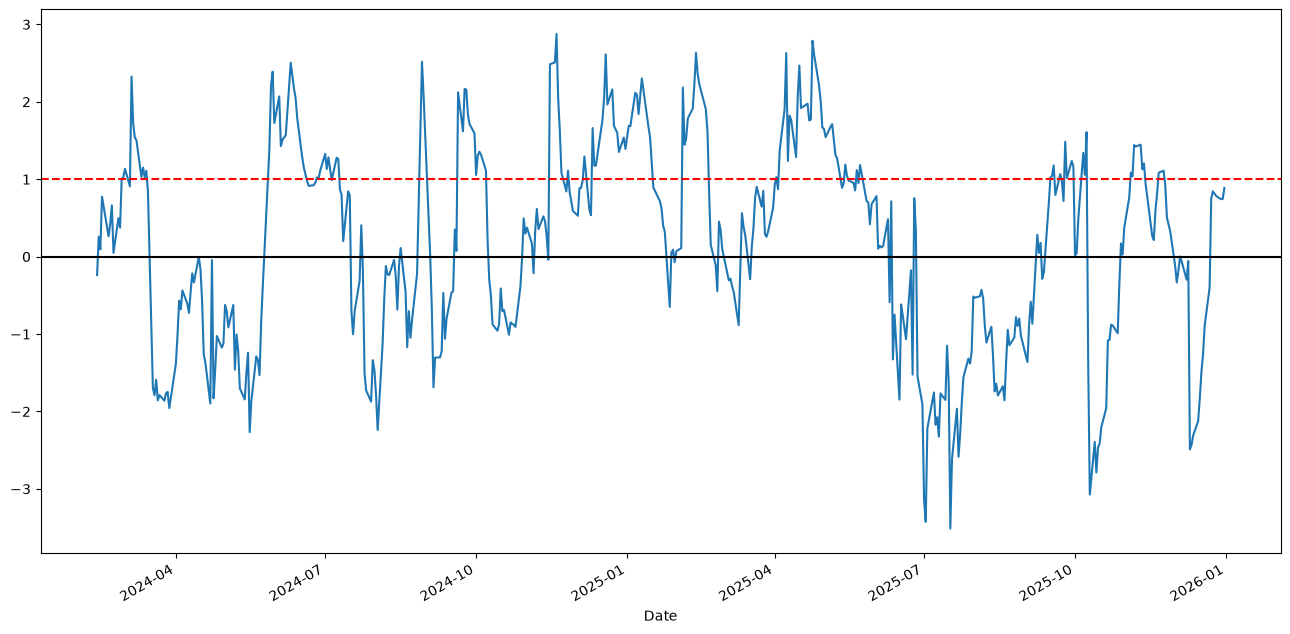

In [28]:
zscore_30_1.plot(figsize=(16,8), label='Rolling 30 Day Z Score')
plt.axhline(0, color='black')
plt.axhline(1.0, color='r', ls='--')